# C1 · Mental-health emergency visits, community follow-up and acute psychiatric beds by Health Service (Chile, 2024)

**Group 01 · Business Intelligence (IIB423T-1) · Universidad del Desarrollo**

**Main question.** In 2024, how did the 29 public Health Services (*Servicios de Salud*) differ in
mental-health emergency visits, community mental-health follow-up visits and acute psychiatric
bed use, and which of these three areas deserves a closer look in each Service?

**Proposed user and decision.** The mental-health unit of a Health Service (or the MINSAL
department that compares Services) deciding where to review first: access to community care,
hospital capacity, or the way emergency and hospital care are organised.

**Run order.** `analysis/extract_c1_inputs.py` builds the files in `data/` from the DEIS downloads
(already included). Then run this notebook top to bottom from `analysis/`. Outputs are written to
`data/` (prepared tables) and `report/figures/`.

All counts are **visits or bed-days, not people**. The period is calendar year 2024.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
DATA = ROOT / "data"
FIG = ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | "
      f"numpy {np.__version__} | matplotlib {matplotlib.__version__}")

Python 3.11.15 | pandas 3.0.2 | numpy 2.4.4 | matplotlib 3.10.9


## 1. Sources and what one row represents

| File in `data/` | Source (DEIS/MINSAL) | One row = | Filter applied by `extract_c1_inputs.py` |
|---|---|---|---|
| `sadu_2024_mental_health_extract.csv.gz` | Atenciones de Urgencia 2024 (`AtencionesUrgencia2024.csv`) | one facility × day × cause, with visit counts by age band | `IdCausa` in 1, 7, 8, 22, 23, 25, 27, 28, 32, 33, 35–42 |
| `rem20_2024_psychiatry_extract.csv` | REM20 hospital indicators (`indicadores_rem20_20260825.csv`) | one hospital × functional area × month | `PERIODO` = 2024 and area name contains "Psiquiatr" |
| `rem_a06_2024_mh_controls_extract.csv` | REM Serie A 2024 (`SerieA2024.csv`), sheet A06 section A.1 | one facility × month × activity code (professional) | 10 codes of section A.1 "Controles de salud mental" |
| `establecimientos_20260910.csv` | DEIS facility registry, snapshot 2026-09-10 | one facility | none (full file) |

The extracts copy source lines unchanged; all corrections happen below and are counted.

In [2]:
sadu = pd.read_csv(DATA / "sadu_2024_mental_health_extract.csv.gz", sep=";",
                   dtype={"IdEstablecimiento": str})
rem20 = pd.read_csv(DATA / "rem20_2024_psychiatry_extract.csv", sep=";",
                    dtype={"COD_SSS": str, "CODIGO_ESTABLECIMIENTO": str})
a06 = pd.read_csv(DATA / "rem_a06_2024_mh_controls_extract.csv", sep=";",
                  dtype={"IdEstablecimiento": str, "CodigoPrestacion": str})
reg = pd.read_csv(DATA / "establecimientos_20260910.csv", sep=";", dtype=str)

for name, df in [("SADU", sadu), ("REM20", rem20), ("REM A06", a06), ("Registry", reg)]:
    print(f"{name:9s} {df.shape[0]:>9,} rows x {df.shape[1]} columns")

SADU      4,037,964 rows x 21 columns
REM20           934 rows x 20 columns
REM A06      72,522 rows x 57 columns
Registry      5,743 rows x 33 columns


## 2. Profiling the emergency-visit source (SADU)

### 2.1 Types, nulls, keys and age cross-sum

In [3]:
AGE = ["Menores_1", "De_1_a_4", "De_5_a_14", "De_15_a_64", "De_65_y_mas"]
print(sadu.dtypes.to_string())
nulls = sadu.isna().sum()
print("\nColumns with nulls:\n", nulls[nulls > 0].to_string())
print("\nNegative counts:", int((sadu[AGE + ["Total"]] < 0).sum().sum()))
print("Rows where Total != sum of age bands:",
      int((sadu[AGE].sum(axis=1) != sadu["Total"]).sum()))
print("Codes with leading/trailing spaces:",
      sadu.loc[sadu["IdEstablecimiento"] != sadu["IdEstablecimiento"].str.strip(),
               "IdEstablecimiento"].nunique())
key = ["IdEstablecimiento", "fecha", "IdCausa"]
print("Duplicated facility-day-cause keys:", int(sadu.duplicated(key).sum()),
      "| fully identical rows:", int(sadu.duplicated().sum()))

IdEstablecimiento               str
NEstablecimiento                str
IdCausa                       int64
GlosaCausa                      str
Total                         int64
Menores_1                     int64
De_1_a_4                      int64
De_5_a_14                     int64
De_15_a_64                    int64
De_65_y_mas                   int64
fecha                           str
semana                        int64
GLOSATIPOESTABLECIMIENTO        str
GLOSATIPOATENCION               str
GlosaTipoCampana                str
CodigoRegion                float64
NombreRegion                    str
CodigoDependencia           float64
NombreDependencia               str
CodigoComuna                float64
NombreComuna                    str



Columns with nulls:
 NEstablecimiento     23238
CodigoRegion          3474
NombreRegion          3474
CodigoDependencia     3474
NombreDependencia     3474
CodigoComuna          3474
NombreComuna          3474

Negative counts: 0


Rows where Total != sum of age bands: 0


Codes with leading/trailing spaces: 28


Duplicated facility-day-cause keys: 24 | fully identical rows: 24


### 2.2 Cause hierarchy: which rows can be added together

The SADU cause list mixes totals and components. Adding a total to its parts double-counts
visits, so the hierarchy is checked on every facility-day before choosing measures.

In [4]:
cause_names = (sadu.drop_duplicates("IdCausa").set_index("IdCausa")["GlosaCausa"]
               .str.slice(0, 70).sort_index())
display(cause_names.to_frame("GlosaCausa"))

wide = sadu.drop_duplicates().pivot_table(index=["IdEstablecimiento", "fecha"],
                                          columns="IdCausa", values="Total",
                                          aggfunc="sum")
checks = {
    "36 = 37+38+39+40+41 (mental-health visits)": wide[36] - wide[[37, 38, 39, 40, 41]].sum(axis=1),
    "25 = 7+8+22+23+32+33+42 (ED hospitalisations)": wide[25] - wide[[7, 8, 22, 23, 32, 33, 42]].sum(axis=1),
}
for label, diff in checks.items():
    print(f"{label}: {int((diff != 0).sum())} facility-days differ out of {diff.notna().sum():,}")

totals = sadu.drop_duplicates().groupby("IdCausa")["Total"].sum()
print("\nPatients waiting for a bed (27) total:", int(totals[27]),
      "| waiting < 12 h (28) total:", int(totals[28]))

,GlosaCausa
IdCausa,
1,SECCIÓN 1. TOTAL ATENCIONES DE URGENCIA
7,CAUSAS SISTEMA RESPIRATORIO
8,- LAS DEMÁS CAUSAS
22,- CAUSAS SISTEMA CIRCULATORIO
23,- TRAUMATISMOS Y ENVENENAMIENTOS
25,SECCIÓN 2. TOTAL DE HOSPITALIZACIONES
27,Pacientes en espera de hospitalización
28,Pacientes en espera de hospitalización que esp...
32,"- COVID-19, VIRUS IDENTIFICADO U07.1"


36 = 37+38+39+40+41 (mental-health visits): 0 facility-days differ out of 224,330
25 = 7+8+22+23+32+33+42 (ED hospitalisations): 0 facility-days differ out of 224,330



Patients waiting for a bed (27) total: 0 | waiting < 12 h (28) total: 0


**Result.** Cause 36 equals the sum of 37–41 on every facility-day, so it is the mental-health
visit total and **includes suicidal ideation (R45.8, cause 37)**. Self-harm (X60–X84, cause 35) is
an injury code outside 36 and is reported separately. Cause 42 is not a visit cause: it is the
mental-disorder component of cause 25 (hospitalisations decided in the emergency department).
Causes 27 and 28 (patients waiting for a bed) are recorded as zero everywhere in 2024; they are
recorded zeros, not observed waiting, so waiting cannot be measured from this source.

W1 added causes 35, 37, 39 and 40 and presented them as "acute" visits. C1 uses 36 as the
mental-health visit total and keeps 35 as a separate line.

### 2.3 Reporting coverage (missing days versus recorded zeros)

In [5]:
days = sadu.groupby(sadu["IdEstablecimiento"].str.strip())["fecha"].nunique()
cov = days.describe()[["count", "min", "50%", "max"]]
print(cov.to_string())
print("Facilities with all 366 days:", int((days == 366).sum()),
      "| with fewer than 366:", int((days < 366).sum()),
      "| with fewer than 300:", int((days < 300).sum()))
zero_share = (sadu.loc[sadu["IdCausa"] == 36, "Total"] == 0).mean()
print(f"Facility-days with a recorded zero in cause 36: {zero_share:.1%}")

count    640.0
min        2.0
50%      366.0
max      366.0
Facilities with all 366 days: 452 | with fewer than 366: 188 | with fewer than 300: 40
Facility-days with a recorded zero in cause 36: 47.3%


A missing day means the facility sent no row for that day; a zero means it reported no
mental-health visit. Most facilities report every day. Facilities with fewer days are kept as
reported: SADU does not say whether a missing day is a closed service or a reporting gap, and
imputing visits would add numbers nobody observed.

## 3. Preparation

1. Strip whitespace from `IdEstablecimiento` (28 legacy codes carry trailing spaces).
2. Drop the 24 fully identical duplicate rows (two facility-days reported twice: `17-913` on
   11 Feb and `28-900` on 24 Dec).
3. Fill the Health Service of facility `17-803` (SAPU Ultraestación), whose territorial and name
   fields are blank on all its rows, from the facility registry.

In [6]:
before = len(sadu), int(sadu.loc[sadu["IdCausa"] == 36, "Total"].sum())
sadu["IdEstablecimiento"] = sadu["IdEstablecimiento"].str.strip()
sadu = sadu.drop_duplicates().copy()

blank = sadu["CodigoDependencia"].isna()
known = (reg.dropna(subset=["EstablecimientoCodigoAntiguo"])
         .set_index("EstablecimientoCodigoAntiguo")["SeremiSaludCodigo_ServicioDeSaludCodigo"]
         .astype(float))
print("Rows with blank Health Service:", int(blank.sum()),
      "| facilities:", sadu.loc[blank, "IdEstablecimiento"].unique().tolist())
sadu.loc[blank, "CodigoDependencia"] = sadu.loc[blank, "IdEstablecimiento"].map(known)
print("Registry name:", reg.loc[reg["EstablecimientoCodigoAntiguo"] == "17-803", "EstablecimientoGlosa"].tolist(),
      "| blank after filling:", int(sadu["CodigoDependencia"].isna().sum()))
sadu["ss"] = sadu["CodigoDependencia"].astype(int)

after = len(sadu), int(sadu.loc[sadu["IdCausa"] == 36, "Total"].sum())
print(f"Rows {before[0]:,} -> {after[0]:,} | mental-health visits (36) {before[1]:,} -> {after[1]:,}")

Rows with blank Health Service: 3474 | facilities: ['17-803']
Registry name: ['SAPU Ultraestación'] | blank after filling: 0
Rows 4,037,964 -> 4,037,940 | mental-health visits (36) 305,432 -> 305,431


## 4. Facility join: SADU → registry (the 640 versus 609 question)

W1 reported "640/640 matched" in the report and "609 (95.2%)" in the notebook. Both numbers
come from the same data: SADU uses two code systems. The join is tested with the expected
cardinality **many SADU rows : 1 registry facility**.

In [7]:
fac = sadu.drop_duplicates("IdEstablecimiento")[
    ["IdEstablecimiento", "NEstablecimiento", "GLOSATIPOESTABLECIMIENTO", "ss"]].copy()
legacy = reg.dropna(subset=["EstablecimientoCodigoAntiguo"])
print("Registry: EstablecimientoCodigo unique:", reg["EstablecimientoCodigo"].is_unique)
bad_legacy = ~legacy["EstablecimientoCodigoAntiguo"].str.match(r"^\d{2}-\d{3}$")
print("Registry legacy codes not in NN-NNN form:", int(bad_legacy.sum()),
      legacy.loc[bad_legacy, "EstablecimientoCodigoAntiguo"].tolist())

fac["by_legacy"] = fac["IdEstablecimiento"].isin(legacy["EstablecimientoCodigoAntiguo"])
fac["by_modern"] = fac["IdEstablecimiento"].isin(reg["EstablecimientoCodigo"])
fac["code_system"] = np.select([fac["by_legacy"], fac["by_modern"]],
                               ["legacy NN-NNN", "modern 6-digit"], "unmatched")
bridge = pd.concat([
    legacy.set_index("EstablecimientoCodigoAntiguo")["EstablecimientoCodigo"],
    reg.set_index("EstablecimientoCodigo", drop=False)["EstablecimientoCodigo"]])
bridge = bridge[~bridge.index.duplicated()]
fac["EstablecimientoCodigo"] = fac["IdEstablecimiento"].map(bridge)

summary = fac["code_system"].value_counts().to_frame("SADU facilities")
display(summary)
print("SADU facilities:", len(fac),
      "| distinct registry facilities reached:", fac["EstablecimientoCodigo"].nunique())

Registry: EstablecimientoCodigo unique: True
Registry legacy codes not in NN-NNN form: 13 ['12-Jan', '12-Apr', '11-Apr', '11-Aug', '11-Dec', '30-Dec', '10-Dec', '30-Aug', '10-Aug', '30-Apr', '10-Apr', '30-Jan', '10-Jan']


,SADU facilities
code_system,
legacy NN-NNN,609
modern 6-digit,31


SADU facilities: 640 | distinct registry facilities reached: 640


In [8]:
fac = fac.merge(reg[["EstablecimientoCodigo", "SeremiSaludCodigo_ServicioDeSaludCodigo",
                     "TipoUrgencia", "NivelComplejidadEstabGlosa", "ComunaGlosa"]],
                on="EstablecimientoCodigo", how="left", validate="many_to_one")
fac["ss_registry"] = pd.to_numeric(fac["SeremiSaludCodigo_ServicioDeSaludCodigo"])
diff_ss = fac[fac["ss"] != fac["ss_registry"]]
print("Facilities whose SADU Health Service differs from the 2026 registry:", len(diff_ss))
display(diff_ss[["IdEstablecimiento", "NEstablecimiento", "ComunaGlosa", "ss", "ss_registry"]])
share = (sadu[sadu["IdEstablecimiento"].isin(diff_ss["IdEstablecimiento"]) & (sadu["IdCausa"] == 36)]
         ["Total"].sum() / sadu.loc[sadu["IdCausa"] == 36, "Total"].sum())
print(f"Share of mental-health visits at those facilities: {share:.2%}")
fac.to_csv(DATA / "facility_join_check.csv", sep=";", index=False)

Facilities whose SADU Health Service differs from the 2026 registry: 2


,IdEstablecimiento,NEstablecimiento,ComunaGlosa,ss,ss_registry
220,13-807,SAPU Padre Esteban Gumucio,La Granja,13,14
315,15-948,SUR Navidad,Navidad,15,6


Share of mental-health visits at those facilities: 0.12%


**Result.** All 640 SADU facility codes reach exactly one registry facility: 609 through the
legacy code (after stripping spaces) and 31 through the modern 6-digit code, which some
facilities report directly in 2024. No registry facility is reached by two SADU codes, so the
join does not duplicate rows. The 13 malformed registry codes (e.g. `12-Jan`) look like
spreadsheet date conversions; none of them is used by a SADU facility.

Two facilities are assigned to a different Health Service in SADU 2024 than in the 2026
registry. C1 keeps the **SADU 2024 assignment**, because it records where the visit was reported
in the year analysed; the registry is a later snapshot. The effect is below 0.2% of visits.

## 5. Conformed Health Service dimension

The three activity sources use the same numeric Health Service code (1–29, 33) but different
names (e.g. SADU "Iquique" = REM20 "Tarapacá"; SADU "Valdivia" = REM20 "Los Ríos"). Joining
on names would break; joining on codes is checked here.

In [9]:
ss_sadu = sadu.groupby("ss")["NombreDependencia"].agg(lambda x: x.dropna().iloc[0])
ss_rem = rem20.assign(ss=rem20["COD_SSS"].astype(int)).groupby("ss")["GLOSA_SSS"].first()
ss_a06 = set(a06["IdServicio"].astype(int))
dim = pd.concat([ss_sadu.rename("SADU name"), ss_rem.rename("REM20 name")], axis=1)
dim["in REM A06"] = dim.index.isin(ss_a06)
print("Codes: SADU", len(ss_sadu), "| REM20", len(ss_rem), "| REM A06", len(ss_a06),
      "| identical sets:", set(ss_sadu.index) == set(ss_rem.index) == ss_a06)
dim["label"] = dim["REM20 name"]
dim.index.name = "ss"
display(dim[dim["SADU name"].str.lower() != dim["REM20 name"].str.lower()])
dim.to_csv(DATA / "health_service_labels.csv", sep=";")

Codes: SADU 29 | REM20 29 | REM A06 29 | identical sets: True


,SADU name,REM20 name,in REM A06,label
ss,,,,
1,Arica,Arica y Parinacota,True,Arica y Parinacota
2,Iquique,Tarapacá,True,Tarapacá
14,Metropolitano Suroriente,Metropolitano Sur Oriente,True,Metropolitano Sur Oriente
15,Libertador B. O'Higgins,Del Libertador B.O Higgins,True,Del Libertador B.O Higgins
20,Bíobío,Biobío,True,Biobío
22,Valdivia,Los Ríos,True,Los Ríos


## 6. Hospital capacity source (REM20, psychiatric functional areas)

### 6.1 Which areas count as acute psychiatric beds

In [10]:
rem20["AREA"] = rem20["AREA_FUNCIONAL"].str.strip()
area_tab = rem20.groupby("AREA").agg(
    hospitals=("CODIGO_ESTABLECIMIENTO", "nunique"),
    available_bed_days=("DIAS_CAMAS_DISPONIBLES", "sum"),
    occupied_bed_days=("DIAS_CAMAS_OCUPADAS", "sum"),
    discharges=("NUMERO_EGRESOS", "sum"),
    stay_days=("DIAS_ESTADA", "sum"))
area_tab["mean_stay_days"] = area_tab["stay_days"] / area_tab["discharges"]
display(area_tab.round(1))

ACUTE = [
    "Área Psiquiatría Adulto Corta estadía",
    "Área Psiquiatría Infanto-adolescente corta estadía",
    "Área de Hospitalización de Cuidados Intensivos en Psiquiatría Adulto",
    "Área de Hospitalización de Cuidados Intensivos en Psiquiatría Infanto Adolescente",
]
acute = rem20[rem20["AREA"].isin(ACUTE)].copy()
acute["age_group"] = np.where(acute["AREA"].str.contains("Infanto"), "child/adolescent", "adult")
print(f"Acute rows kept: {len(acute)} of {len(rem20)}; "
      f"share of psychiatric available bed-days: "
      f"{acute['DIAS_CAMAS_DISPONIBLES'].sum() / rem20['DIAS_CAMAS_DISPONIBLES'].sum():.1%}")

,hospitals,available_bed_days,occupied_bed_days,discharges,stay_days,mean_stay_days
AREA,,,,,,
Área Psiquiatría Adulto Corta estadía,28,276632,253687,10087,258423,25.6
Área Psiquiatría Adulto Larga estadía,3,43868,40937,55,75857,1379.2
Área Psiquiatría Adulto Mediana estadía,3,51240,43288,204,48994,240.2
Área Psiquiatría Forense Adulto evaluación e inicio tto.,4,29849,27345,89,23867,268.2
Área Psiquiatría Forense Adulto tratamiento,3,46945,46471,72,48734,676.9
Área Psiquiatría Forense Infanto Adolescente tratamiento,2,5282,3570,98,3373,34.4
Área Psiquiatría Infanto-adolescente corta estadía,21,63946,53628,3036,57362,18.9
Área Psiquiatría Infanto-adolescente mediana estadía,1,1334,1171,23,1151,50.0
Área de Hospitalización de Cuidados Intensivos en Psiquiatría Adulto,10,56261,47805,2644,44836,17.0


Acute rows kept: 745 of 934; share of psychiatric available bed-days: 69.8%


An emergency visit can lead to a short-stay or psychiatric intensive-care admission; medium- and
long-stay and forensic areas follow other referral routes (mean stays of months or court orders).
C1 therefore uses the four acute areas. W1 used adult short-stay, child/adolescent short-stay
and adult **long-stay**, and omitted the two psychiatric intensive-care areas; section 9.3 shows
the effect of that change.

### 6.2 Quality checks

In [11]:
print("Nulls in acute rows:", int(acute.isna().sum().sum()))
print("Duplicated hospital-area-month keys:",
      int(acute.duplicated(["CODIGO_ESTABLECIMIENTO", "COD_AREA_FUNCIONAL", "MES"]).sum()))
zero_avail = acute["DIAS_CAMAS_DISPONIBLES"] == 0
print("Rows with zero available bed-days:", int(zero_avail.sum()))
calc = acute.loc[~zero_avail, "DIAS_CAMAS_OCUPADAS"] / acute.loc[~zero_avail, "DIAS_CAMAS_DISPONIBLES"] * 100
print("Rows where recomputed occupancy differs from INDICE_OCUPACIONAL by > 0.1 pt:",
      int((calc - acute.loc[~zero_avail, "INDICE_OCUPACIONAL"]).abs().gt(0.1).sum()))
print("Rows with occupied > available bed-days:",
      int((acute["DIAS_CAMAS_OCUPADAS"] > acute["DIAS_CAMAS_DISPONIBLES"]).sum()))
months = acute.groupby(["CODIGO_ESTABLECIMIENTO", "AREA"])["MES"].nunique()
print("Hospital-area units by number of months reported:", months.value_counts().sort_index().to_dict())
print("TIPO_PERTENENCIA values:", acute["TIPO_PERTENENCIA"].unique().tolist(), "(1 = public network)")

child_short = rem20[rem20["AREA"] == "Área Psiquiatría Infanto-adolescente corta estadía"]
child_any = acute[acute["age_group"] == "child/adolescent"]
print("Health Services with child/adolescent short-stay bed-days:", child_short["COD_SSS"].nunique(),
      "| with any acute child/adolescent area:", child_any["COD_SSS"].nunique(), "of 29")

Nulls in acute rows: 0
Duplicated hospital-area-month keys: 0
Rows with zero available bed-days: 7
Rows where recomputed occupancy differs from INDICE_OCUPACIONAL by > 0.1 pt: 0
Rows with occupied > available bed-days: 14
Hospital-area units by number of months reported: {6: 1, 7: 1, 8: 2, 10: 1, 11: 2, 12: 57}
TIPO_PERTENENCIA values: [1] (1 = public network)
Health Services with child/adolescent short-stay bed-days: 18 | with any acute child/adolescent area: 22 of 29


W1 stated that 18 of 29 Services had no child/adolescent psychiatric beds. REM20 2024 shows the
reverse: 18 Services report child/adolescent short-stay bed-days and 11 do not. Counting the
psychiatric intensive-care areas as well, 22 Services report an acute child/adolescent area and
7 report none. A Service without such an area in REM20 may still refer
children to another Service's hospital; REM20 does not record referrals, so the finding is
"not reported in REM20", not "no service".

Occupancy is aggregated as **sum of occupied bed-days / sum of available bed-days**, not as a
mean of monthly percentages, so months and hospitals with more beds weigh more and the 7
zero-bed months do not produce undefined values. The 14 rows with more occupied than available
bed-days are kept as reported (extra beds in use are a plausible cause, but REM20 does not
record it). Seven hospital-area units report fewer than 12 months; REM20 does not say why,
so their bed-days are used as reported.

## 7. Community follow-up source (REM A06, section A.1)

`Col01` is the total of mental-health follow-up visits ("controles") for both sexes; `Col02` and
`Col03` split it by sex. The ten codes are the professionals who deliver the visit.

In [12]:
cols = ["Col01", "Col02", "Col03"]
print("Nulls:", a06[cols].isna().sum().to_dict())
mismatch = a06["Col01"].fillna(0) != a06["Col02"].fillna(0) + a06["Col03"].fillna(0)
print("Rows where Col01 != Col02 + Col03:", int(mismatch.sum()),
      "| visits involved:", int(a06.loc[mismatch, "Col01"].sum()))
print("Duplicated facility-month-code keys:",
      int(a06.duplicated(["Mes", "IdEstablecimiento", "CodigoPrestacion"]).sum()))
print("Facilities:", a06["IdEstablecimiento"].nunique(),
      "| found in registry:", f"{a06['IdEstablecimiento'].isin(reg['EstablecimientoCodigo']).mean():.1%}")

a06 = a06.merge(reg[["EstablecimientoCodigo", "NivelAtencionEstabglosa", "TipoEstablecimientoGlosa"]],
                left_on="IdEstablecimiento", right_on="EstablecimientoCodigo",
                how="left", validate="many_to_one")
a06["level"] = np.where(a06["NivelAtencionEstabglosa"] == "Primer Nivel", "primary care",
                        "specialty / other")
a06["ss"] = a06["IdServicio"].astype(int)
display(a06.groupby("level")["Col01"].sum().to_frame("follow-up visits"))
display(a06.groupby("TipoEstablecimientoGlosa")["Col01"].sum().sort_values(ascending=False)
        .head(6).to_frame("follow-up visits"))

Nulls: {'Col01': 5, 'Col02': 5, 'Col03': 5}
Rows where Col01 != Col02 + Col03: 7 | visits involved: 177
Duplicated facility-month-code keys: 0
Facilities: 2296 | found in registry: 100.0%


,follow-up visits
level,
primary care,4005235.0
specialty / other,1309818.0


,follow-up visits
TipoEstablecimientoGlosa,
Centro de Salud Familiar (CESFAM),3180192.0
Hospital,844467.0
Centro Comunitario de Salud Mental (COSAM),643468.0
Centro Comunitario de Salud Familiar (CECOSF),256960.0
Posta de Salud Rural (PSR),231085.0
Otro,56988.0


The 5 null rows are left as missing (not zero) and add nothing to the totals. The rows where
`Col01` differs from the sex split are kept; `Col01` is the published total. REM A06 counts
visits delivered in each Service, not people and not the population registered there.

## 8. National picture: from all emergency visits to psychiatric beds (2024)

In [13]:
t = sadu.groupby("IdCausa")["Total"].sum()
hosp_ed = sadu["GLOSATIPOESTABLECIMIENTO"] == "Hospital"
mh_hosp_ed = int(sadu.loc[hosp_ed & (sadu["IdCausa"] == 36), "Total"].sum())
funnel = pd.DataFrame([
    ("All emergency visits (SADU 1)", t[1], "visits"),
    ("Mental-health visits, F00-F99 + R45.8 (SADU 36)", t[36], "visits"),
    ("  of which at hospital emergency departments", mh_hosp_ed, "visits"),
    ("Self-harm visits, X60-X84 (SADU 35)", t[35], "visits"),
    ("ED hospitalisations for mental disorders (SADU 42)", t[42], "hospitalisations"),
    ("Discharges from acute psychiatric areas (REM20)", acute["NUMERO_EGRESOS"].sum(), "discharges"),
    ("Available acute psychiatric bed-days (REM20)", acute["DIAS_CAMAS_DISPONIBLES"].sum(), "bed-days"),
    ("Mental-health follow-up visits (REM A06 A.1)", a06["Col01"].sum(), "visits"),
], columns=["Measure", "Value", "Unit"])
funnel["Value"] = funnel["Value"].astype(int)
display(funnel.style.format({"Value": "{:,}"}).hide(axis="index"))
print(f"Mental-health share of all emergency visits: {t[36] / t[1]:.2%}")
print(f"ED hospitalisations for mental disorders per 100 mental-health visits at hospital EDs: "
      f"{t[42] / mh_hosp_ed * 100:.1f}")
print(f"Acute psychiatric occupancy: "
      f"{acute['DIAS_CAMAS_OCUPADAS'].sum() / acute['DIAS_CAMAS_DISPONIBLES'].sum():.1%}")
print(f"Average available acute psychiatric beds: {acute['DIAS_CAMAS_DISPONIBLES'].sum() / 366:,.0f}")

Measure,Value,Unit
All emergency visits (SADU 1),"19,436,048",visits
"Mental-health visits, F00-F99 + R45.8 (SADU 36)","305,431",visits
of which at hospital emergency departments,"158,027",visits
"Self-harm visits, X60-X84 (SADU 35)","9,753",visits
ED hospitalisations for mental disorders (SADU 42),"27,306",hospitalisations
Discharges from acute psychiatric areas (REM20),"16,427",discharges
Available acute psychiatric bed-days (REM20),"413,486",bed-days
Mental-health follow-up visits (REM A06 A.1),"5,315,053",visits


Mental-health share of all emergency visits: 1.57%
ED hospitalisations for mental disorders per 100 mental-health visits at hospital EDs: 17.3
Acute psychiatric occupancy: 89.3%
Average available acute psychiatric beds: 1,130


The measures come from different sources and different counting units. They are shown side by
side, not linked: an ED hospitalisation for a mental disorder is not necessarily an admission to
a psychiatric bed, and a REM20 discharge may come from a planned admission.

,Menores_1,De_1_a_4,De_5_a_14,De_15_a_64,De_65_y_mas,Total
IdCausa,,,,,,
Anxiety and stress-related (F40-F48),55,132,10704,144418,18621,173930
Other mental disorders,124,678,6075,42557,10367,59801
Mood disorders (F30-F39),8,28,3342,25385,1871,30634
Substance use (F10-F19),47,183,662,26572,1169,28633
Suicidal ideation (R45.8),0,0,2141,9989,303,12433
Self-harm (X60-X84),0,0,1490,7952,311,9753


,Menores_1,De_1_a_4,De_5_a_14,De_15_a_64,De_65_y_mas
IdCausa,,,,,
Anxiety and stress-related (F40-F48),0.0,0.1,6.2,83.0,10.7
Other mental disorders,0.2,1.1,10.2,71.2,17.3
Mood disorders (F30-F39),0.0,0.1,10.9,82.9,6.1
Substance use (F10-F19),0.2,0.6,2.3,92.8,4.1
Suicidal ideation (R45.8),0.0,0.0,17.2,80.3,2.4
Self-harm (X60-X84),0.0,0.0,15.3,81.5,3.2


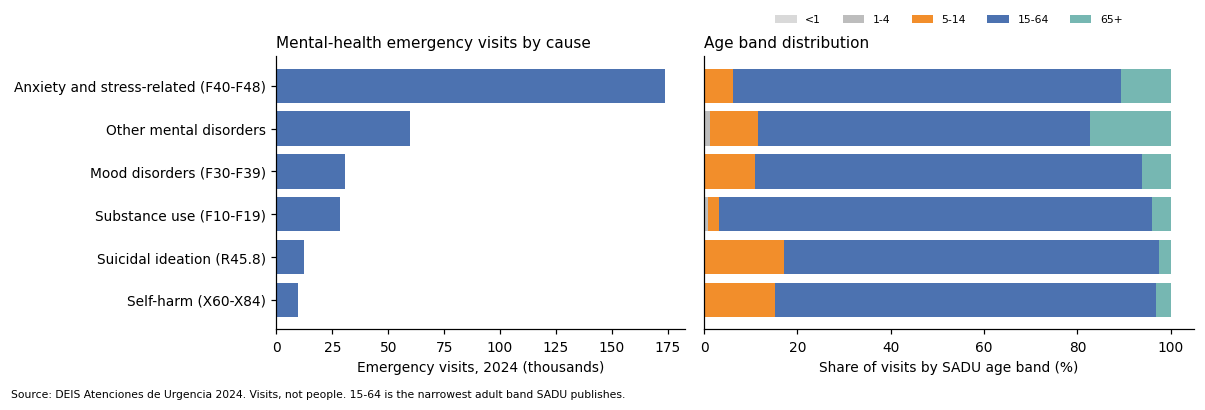

In [14]:
mh = sadu[sadu["IdCausa"].isin([35, 37, 38, 39, 40, 41])]
CAUSE_EN = {35: "Self-harm (X60-X84)", 37: "Suicidal ideation (R45.8)",
            38: "Substance use (F10-F19)", 39: "Mood disorders (F30-F39)",
            40: "Anxiety and stress-related (F40-F48)", 41: "Other mental disorders"}
by_cause = mh.groupby("IdCausa")[AGE].sum().rename(index=CAUSE_EN)
by_cause["Total"] = by_cause.sum(axis=1)
by_cause = by_cause.sort_values("Total")
age_pct = by_cause[AGE].div(by_cause["Total"], axis=0) * 100
display(by_cause.sort_values("Total", ascending=False))
display(age_pct.round(1).iloc[::-1])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 1.2]})
axes[0].barh(by_cause.index, by_cause["Total"] / 1000, color="#4C72B0")
axes[0].set_xlabel("Emergency visits, 2024 (thousands)")
axes[0].set_title("Mental-health emergency visits by cause", loc="left", fontsize=10)
labels = ["<1", "1-4", "5-14", "15-64", "65+"]
colors = ["#d9d9d9", "#bdbdbd", "#F28E2B", "#4C72B0", "#76B7B2"]
left = np.zeros(len(age_pct))
for col, lab, colr in zip(AGE, labels, colors):
    axes[1].barh(age_pct.index, age_pct[col], left=left, color=colr, label=lab)
    left += age_pct[col].values
axes[1].set_yticks([])
axes[1].set_xlabel("Share of visits by SADU age band (%)")
axes[1].set_title("Age band distribution", loc="left", fontsize=10)
axes[1].legend(ncol=5, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, 1.08), frameon=False)
fig.text(0.01, -0.02, "Source: DEIS Atenciones de Urgencia 2024. Visits, not people. "
         "15-64 is the narrowest adult band SADU publishes.", fontsize=7)
plt.tight_layout()
fig.savefig(FIG / "fig1_mh_visits_cause_age.png", bbox_inches="tight")
plt.show()

Anxiety and stress-related disorders (F40–F48) account for most mental-health emergency visits;
suicidal ideation and self-harm together are about 7% of the 36+35 total. The 15–64 band holds
most visits in every cause, and the 5–14 band has a larger share of suicidal ideation and
self-harm than of other causes. The 15–64 band includes adolescents aged 15–17 and cannot be
split with these totals.

,1,2,3,4,5,6,7,8,9,10,11,12
mh_visits_per_day,831.9,842.6,863.0,842.2,739.5,809.0,819.0,834.7,838.0,891.5,891.6,813.2
acute_occupancy_pct,89.8,86.4,88.4,89.9,89.9,90.9,89.4,89.8,89.9,91.4,90.1,85.3


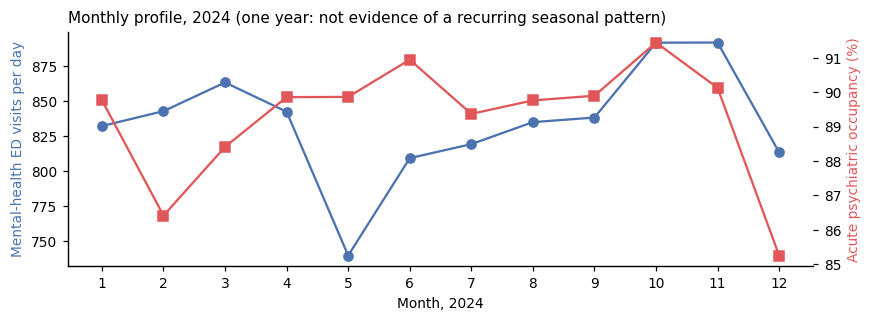

In [15]:
month = pd.to_datetime(sadu["fecha"], format="%d/%m/%Y").dt.month
m_vis = sadu[sadu["IdCausa"] == 36].groupby(month[sadu["IdCausa"] == 36])["Total"].sum()
m_days = pd.Series(pd.date_range("2024-01-01", "2024-12-31").month).value_counts().sort_index()
m_occ = acute.groupby("MES")[["DIAS_CAMAS_OCUPADAS", "DIAS_CAMAS_DISPONIBLES"]].sum()
monthly = pd.DataFrame({
    "mh_visits_per_day": m_vis / m_days,
    "acute_occupancy_pct": m_occ["DIAS_CAMAS_OCUPADAS"] / m_occ["DIAS_CAMAS_DISPONIBLES"] * 100})
display(monthly.round(1).T)

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(monthly.index, monthly["mh_visits_per_day"], marker="o", color="#4C72B0")
ax.set_ylabel("Mental-health ED visits per day", color="#4C72B0")
ax.set_xticks(range(1, 13))
ax.set_xlabel("Month, 2024")
ax2 = ax.twinx()
ax2.plot(monthly.index, monthly["acute_occupancy_pct"], marker="s", color="#E15759")
ax2.set_ylabel("Acute psychiatric occupancy (%)", color="#E15759")
ax2.spines["top"].set_visible(False)
ax.set_title("Monthly profile, 2024 (one year: not evidence of a recurring seasonal pattern)",
             loc="left", fontsize=10)
plt.tight_layout()
fig.savefig(FIG / "fig4_monthly_2024.png", bbox_inches="tight")
plt.show()

Visits per day and occupancy move within a narrow range across 2024. With one year there is no
basis for a seasonal claim; comparable years (SADU 2021–2023 are available) would be needed.

## 9. Health Service profiles

### 9.1 Indicators

| Indicator | Numerator | Denominator | Unit | Source |
|---|---|---|---|---|
| Mental-health share of ED visits | SADU cause 36 visits | SADU cause 1 visits | % of visits | SADU |
| ED hospitalisation for mental disorders | SADU cause 42 | SADU cause 36 visits at hospital EDs | per 100 visits | SADU |
| Acute psychiatric beds | acute available bed-days | 366 days | average beds | REM20 |
| Acute psychiatric occupancy | acute occupied bed-days | acute available bed-days | % | REM20 |
| Community follow-up intensity | REM A06 A.1 follow-up visits | SADU cause 36 visits | visits per ED visit | A06 + SADU |

Population rates are not computed: visits are counted where care happened, which is not the
patients' residence, and no population file with the same territorial unit is part of this case.

In [16]:
g = sadu.pivot_table(index="ss", columns="IdCausa", values="Total", aggfunc="sum")
hosp = sadu[hosp_ed & (sadu["IdCausa"] == 36)].groupby("ss")["Total"].sum()
ac = acute.assign(ss=acute["COD_SSS"].astype(int))
bed = ac.groupby("ss")[["DIAS_CAMAS_DISPONIBLES", "DIAS_CAMAS_OCUPADAS", "NUMERO_EGRESOS"]].sum()
child = ac[ac["age_group"] == "child/adolescent"].groupby("ss")["DIAS_CAMAS_DISPONIBLES"].sum()
ctl = a06.pivot_table(index="ss", columns="level", values="Col01", aggfunc="sum")

hs = pd.DataFrame({
    "health_service": dim["label"],
    "ed_visits_all": g[1],
    "mh_visits": g[36],
    "selfharm_visits": g[35],
    "mh_share_pct": g[36] / g[1] * 100,
    "mh_visits_hospital_ed": hosp,
    "ed_mh_hospitalisations": g[42],
    "ed_mh_hosp_per_100": g[42] / hosp * 100,
    "acute_beds_avg": bed["DIAS_CAMAS_DISPONIBLES"] / 366,
    "child_acute_beds_avg": child / 366,
    "acute_occupancy_pct": bed["DIAS_CAMAS_OCUPADAS"] / bed["DIAS_CAMAS_DISPONIBLES"] * 100,
    "acute_discharges": bed["NUMERO_EGRESOS"],
    "followup_visits_primary": ctl["primary care"],
    "followup_visits_specialty": ctl["specialty / other"],
})
hs[["acute_beds_avg", "child_acute_beds_avg", "acute_discharges"]] = \
    hs[["acute_beds_avg", "child_acute_beds_avg", "acute_discharges"]].fillna(0)
hs["followup_per_mh_visit"] = (hs["followup_visits_primary"] + hs["followup_visits_specialty"]) / hs["mh_visits"]
hs.index.name = "ss"
print("Health Services:", len(hs), "| totals reconcile with national figures:",
      int(hs["mh_visits"].sum()) == int(t[36]), int(hs["ed_mh_hospitalisations"].sum()) == int(t[42]))
hs.round(2).to_csv(DATA / "health_service_profile_2024.csv", sep=";")
display(hs.drop(columns=["selfharm_visits", "followup_visits_primary", "followup_visits_specialty"])
        .sort_values("mh_share_pct", ascending=False).round(1))

Health Services: 29 | totals reconcile with national figures: True True


,health_service,ed_visits_all,mh_visits,mh_share_pct,mh_visits_hospital_ed,ed_mh_hospitalisations,ed_mh_hosp_per_100,acute_beds_avg,child_acute_beds_avg,acute_occupancy_pct,acute_discharges,followup_per_mh_visit
ss,,,,,,,,,,,,
9,Metropolitano Norte,918641,32983,3.6,20022,1560,7.8,230.7,13.6,89.2,2451,8.4
8,Aconcagua,250842,7456,3.0,6470,579,8.9,40.0,0.0,95.4,656,12.8
26,Magallanes,213741,4976,2.3,3437,752,21.9,22.2,8.0,88.2,474,19.2
33,Chiloé,198568,4581,2.3,2811,621,22.1,9.0,0.0,83.9,221,15.2
21,Araucanía Sur,954610,19498,2.0,13093,1436,11.0,62.0,13.3,95.3,674,12.9
24,Del Reloncaví,550536,10877,2.0,6407,1262,19.7,30.0,6.0,99.4,291,11.2
25,Aisén,141702,2616,1.8,2447,770,31.5,18.1,10.0,77.2,432,19.5
29,Araucanía Norte,216768,3922,1.8,3237,23,0.7,17.6,5.6,76.2,200,24.3
19,Talcahuano,527408,9155,1.7,4383,615,14.0,12.0,12.0,77.8,204,14.2


### 9.2 Where visits concentrate inside a Service

A Service's share can reflect one specialised psychiatric emergency department that receives
patients from other Services. The largest facility per Service is checked, and the share is
recomputed without facilities whose name identifies a psychiatric hospital.

In [17]:
fac_mh = (sadu[sadu["IdCausa"] == 36].groupby(["ss", "NEstablecimiento"])["Total"].sum()
          .reset_index().sort_values("Total", ascending=False))
top = fac_mh.groupby("ss").head(1).set_index("ss")
top["share_of_service_mh_visits_pct"] = top["Total"] / hs["mh_visits"] * 100
display(top.sort_values("share_of_service_mh_visits_pct", ascending=False).head(6).round(1))

psych_ed = sadu["NEstablecimiento"].fillna("").str.contains("Psiqui", case=False)
print("Facilities with 'Psiqui' in the name:", sadu.loc[psych_ed, "NEstablecimiento"].unique().tolist())
g2 = sadu[~psych_ed].pivot_table(index="ss", columns="IdCausa", values="Total", aggfunc="sum")
hs["mh_share_excl_psych_ed_pct"] = g2[36] / g2[1] * 100
display(hs[["health_service", "mh_share_pct", "mh_share_excl_psych_ed_pct"]]
        .sort_values("mh_share_pct", ascending=False).head(6).round(2))
hs.round(2).to_csv(DATA / "health_service_profile_2024.csv", sep=";")

,NEstablecimiento,Total,share_of_service_mh_visits_pct
ss,,,
1,Hospital Regional Dr. Juan Noé Crevani (Arica),3145,86.1
25,Hospital Regional (Coihaique),1671,63.9
8,Hospital Psiquiátrico Dr. Philippe Pinel (Puta...,4520,60.6
9,Instituto Psiquiátrico Dr. José Horwitz Barak...,18024,54.6
23,Hospital Base de Osorno,2269,42.3
26,Hospital Dr. Lautaro Navarro Avaria (Punta Are...,2081,41.8


Facilities with 'Psiqui' in the name: ['Instituto Psiquiátrico  Dr. José Horwitz Barak (Santiago, Recoleta)', 'Hospital Psiquiátrico Dr. Philippe Pinel (Putaendo)']


,health_service,mh_share_pct,mh_share_excl_psych_ed_pct
ss,,,
9,Metropolitano Norte,3.59,1.66
8,Aconcagua,2.97,1.19
26,Magallanes,2.33,2.33
33,Chiloé,2.31,2.31
21,Araucanía Sur,2.04,2.04
24,Del Reloncaví,1.98,1.98


**Result.** The two highest shares are driven by specialised psychiatric emergency departments:
Instituto Psiquiátrico Dr. José Horwitz Barak (Metropolitano Norte) and Hospital Psiquiátrico
Dr. Philippe Pinel (Aconcagua) receive over half of their Service's mental-health visits. Without
them both Services fall to the typical range. For these two Services a high share describes how
care is organised (a referral centre), not higher need among local residents.

### 9.3 Comparison across Services

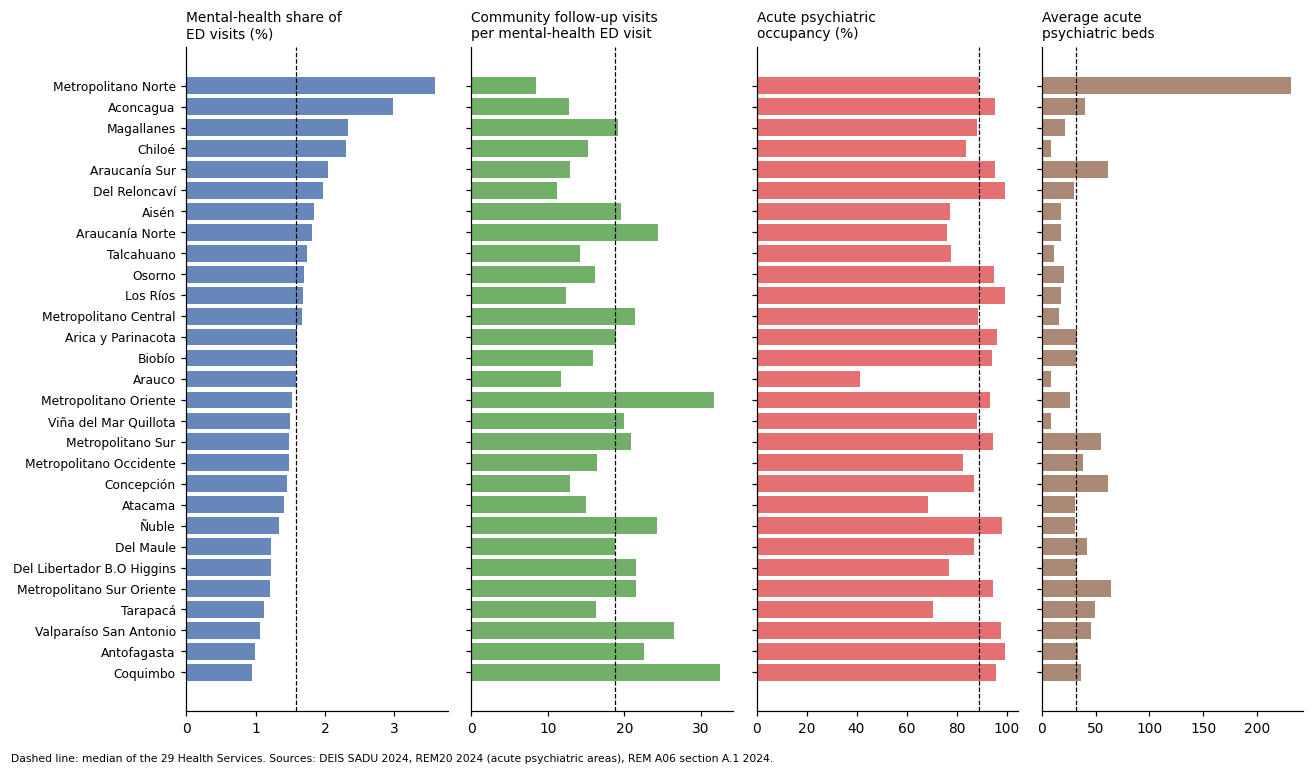

In [18]:
plot = hs.sort_values("mh_share_pct")
panels = [("mh_share_pct", "Mental-health share of\nED visits (%)", "#4C72B0"),
          ("followup_per_mh_visit", "Community follow-up visits\nper mental-health ED visit", "#59A14F"),
          ("acute_occupancy_pct", "Acute psychiatric\noccupancy (%)", "#E15759"),
          ("acute_beds_avg", "Average acute\npsychiatric beds", "#9C755F")]
fig, axes = plt.subplots(1, 4, figsize=(12, 7), sharey=True)
for ax, (col, title, colr) in zip(axes, panels):
    vals = plot[col]
    ax.barh(plot["health_service"], vals.fillna(0), color=colr, alpha=0.85)
    med = hs[col].median()
    ax.axvline(med, color="black", lw=0.8, ls="--")
    ax.set_title(title, fontsize=9, loc="left")
    ax.tick_params(axis="y", labelsize=8)
fig.text(0.01, 0.005, "Dashed line: median of the 29 Health Services. Sources: DEIS SADU 2024, "
         "REM20 2024 (acute psychiatric areas), REM A06 section A.1 2024.", fontsize=7)
plt.tight_layout(rect=(0, 0.02, 1, 1))
fig.savefig(FIG / "fig2_health_service_profiles.png", bbox_inches="tight")
plt.show()

In [19]:
cols = ["mh_share_pct", "followup_per_mh_visit", "acute_occupancy_pct", "ed_mh_hosp_per_100"]
display(hs[cols].describe().loc[["min", "25%", "50%", "75%", "max"]].round(2))
print("Spearman correlations across the 29 Services (descriptive):")
display(hs[cols + ["acute_beds_avg"]].corr(method="spearman").round(2))

,mh_share_pct,followup_per_mh_visit,acute_occupancy_pct,ed_mh_hosp_per_100
min,0.95,8.42,41.47,0.71
25%,1.33,14.16,82.64,14.03
50%,1.58,18.78,89.15,21.11
75%,1.81,21.47,95.40,24.78
max,3.59,32.57,99.58,43.92


Spearman correlations across the 29 Services (descriptive):


,mh_share_pct,followup_per_mh_visit,acute_occupancy_pct,ed_mh_hosp_per_100,acute_beds_avg
mh_share_pct,1.00,-0.56,-0.02,-0.46,-0.33
followup_per_mh_visit,-0.56,1.00,0.10,0.40,-0.02
acute_occupancy_pct,-0.02,0.10,1.00,0.17,0.24
ed_mh_hosp_per_100,-0.46,0.40,0.17,1.00,0.02
acute_beds_avg,-0.33,-0.02,0.24,0.02,1.00


### 9.4 Reconciling with W1: the stress ratio

W1 ranked Services by (causes 35+37+39+40) / (psychiatric bed-days in adult short-stay,
child/adolescent short-stay and adult long-stay). Recomputing it here shows which figures in the
W1 report hold and how the ranking changes with the C1 bed definition. The ratio divides visits
by bed-days, two different units, and most visits do not need a bed, so a value above 1 does not
show a shortage. It is kept only for traceability.

In [20]:
w1_areas = ["Área Psiquiatría Adulto Corta estadía",
            "Área Psiquiatría Infanto-adolescente corta estadía",
            "Área Psiquiatría Adulto Larga estadía"]
w1_num = sadu[sadu["IdCausa"].isin([35, 37, 39, 40])].groupby("ss")["Total"].sum()
w1_den = (rem20[rem20["AREA"].isin(w1_areas)].assign(ss=lambda d: d["COD_SSS"].astype(int))
          .groupby("ss")["DIAS_CAMAS_DISPONIBLES"].sum())
ratio = pd.DataFrame({"health_service": dim["label"],
                      "w1_ratio": w1_num / w1_den,
                      "c1_acute_ratio": w1_num / (bed["DIAS_CAMAS_DISPONIBLES"])})
ratio["w1_rank"] = ratio["w1_ratio"].rank(ascending=False)
ratio["c1_rank"] = ratio["c1_acute_ratio"].rank(ascending=False)
display(ratio.sort_values("w1_rank").head(10).round(2))
print("Services with no bed-days in the W1 areas (ratio undefined):",
      ratio.loc[ratio["w1_ratio"].isna(), "health_service"].tolist())

,health_service,w1_ratio,c1_acute_ratio,w1_rank,c1_rank
ss,,,,,
16,Del Maule,1.83,1.17,1.0,5.0
19,Talcahuano,1.62,1.62,2.0,2.0
11,Metropolitano Central,1.32,1.32,3.0,3.0
10,Metropolitano Occidente,1.31,1.31,4.0,4.0
33,Chiloé,1.04,1.04,5.0,6.0
22,Los Ríos,1.02,1.02,6.0,7.0
28,Arauco,0.91,0.91,7.0,8.0
15,Del Libertador B.O Higgins,0.88,0.88,8.0,9.0
12,Metropolitano Oriente,0.85,0.64,9.0,12.0


Services with no bed-days in the W1 areas (ratio undefined): ['Tarapacá', 'Antofagasta', 'Viña del Mar Quillota', 'Araucanía Norte']


## 10. Where to look first: a descriptive screen

Each Service is compared with the median of the 29 Services on three dimensions. A flag marks a
position worth reviewing, not a performance judgement:

- **Emergency**: mental-health share of ED visits above the median, excluding the two
  psychiatric-hospital EDs (9.2) so that referral centres do not drive the flag.
- **Community**: follow-up visits per mental-health ED visit below the median.
- **Hospital**: acute psychiatric occupancy at or above 90% (all 29 Services report acute beds).

Flags based on the median mark about half the Services by construction. The 90% cut-off is a
reading aid for a high-occupancy position; it is not an official standard
and the screen is re-run with 85% and 95% to show how many flags change.

In [21]:
def screen(df, occ_cut):
    out = pd.DataFrame(index=df.index)
    out["emergency"] = df["mh_share_excl_psych_ed_pct"] > df["mh_share_excl_psych_ed_pct"].median()
    out["community"] = df["followup_per_mh_visit"] < df["followup_per_mh_visit"].median()
    out["hospital"] = df["acute_occupancy_pct"] >= occ_cut
    return out

flags = screen(hs, 90)
flags.insert(0, "health_service", hs["health_service"])
flags["n_flags"] = flags[["emergency", "community", "hospital"]].sum(axis=1)
display(flags.sort_values(["n_flags", "health_service"], ascending=[False, True]))
print("Services by number of flags:", flags["n_flags"].value_counts().sort_index().to_dict())
for cut in (85, 95):
    alt = screen(hs, cut)["hospital"]
    print(f"Hospital flag with {cut}% cut-off: {int(alt.sum())} Services "
          f"(90%: {int(flags['hospital'].sum())}); changed: {int((alt != flags['hospital']).sum())}")
flags.to_csv(DATA / "health_service_screen_2024.csv", sep=";")

,health_service,emergency,community,hospital,n_flags
ss,,,,,
21,Araucanía Sur,True,True,True,3
20,Biobío,True,True,True,3
24,Del Reloncaví,True,True,True,3
22,Los Ríos,True,True,True,3
23,Osorno,True,True,True,3
8,Aconcagua,False,True,True,2
28,Arauco,True,True,False,2
1,Arica y Parinacota,True,False,True,2
33,Chiloé,True,True,False,2


Services by number of flags: {0: 3, 1: 15, 2: 6, 3: 5}
Hospital flag with 85% cut-off: 20 Services (90%: 14); changed: 6
Hospital flag with 95% cut-off: 9 Services (90%: 14); changed: 5


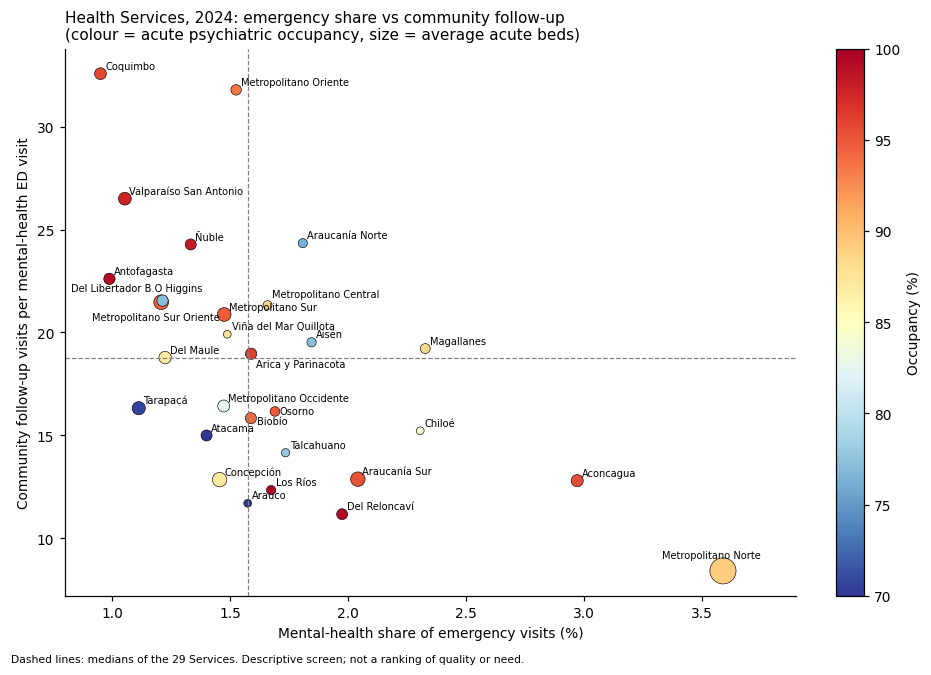

In [22]:
fig, ax = plt.subplots(figsize=(8.5, 6))
sc = ax.scatter(hs["mh_share_pct"], hs["followup_per_mh_visit"],
                c=hs["acute_occupancy_pct"], cmap="RdYlBu_r", vmin=70, vmax=100,
                s=15 + hs["acute_beds_avg"] * 1.2, edgecolor="black", lw=0.4)
ax.set_xlim(0.8, 3.9)
nudge = {14: (-45, -12), 15: (-60, 6), 11: (3, 5), 23: (3, -2), 20: (4, -4), 1: (3, -9),
         9: (-40, 8)}
for ss, r in hs.iterrows():
    ax.annotate(r["health_service"], (r["mh_share_pct"], r["followup_per_mh_visit"]),
                fontsize=6.5, xytext=nudge.get(ss, (3, 3)), textcoords="offset points")
ax.axvline(hs["mh_share_pct"].median(), color="grey", ls="--", lw=0.8)
ax.axhline(hs["followup_per_mh_visit"].median(), color="grey", ls="--", lw=0.8)
ax.set_xlabel("Mental-health share of emergency visits (%)")
ax.set_ylabel("Community follow-up visits per mental-health ED visit")
ax.set_title("Health Services, 2024: emergency share vs community follow-up\n"
             "(colour = acute psychiatric occupancy, size = average acute beds)",
             loc="left", fontsize=10)
cb = plt.colorbar(sc, ax=ax, fraction=0.04)
cb.set_label("Occupancy (%)")
fig.text(0.01, -0.01, "Dashed lines: medians of the 29 Services. Descriptive screen; not a ranking "
         "of quality or need.", fontsize=7)
plt.tight_layout()
fig.savefig(FIG / "fig3_screen_scatter.png", bbox_inches="tight")
plt.show()

## 11. Five Cs summary

| C | Check in this notebook | Result |
|---|---|---|
| Clean | nulls, negatives, age cross-sum, duplicates, key whitespace (2.1, 6.2, 7) | 2 duplicated facility-days removed, 28 codes stripped, 1 facility's blank Service filled; no negatives or cross-sum errors |
| Consistent | cause hierarchy (2.2), recomputed occupancy (6.2), months reported (6.2) | 36 = 37..41 and 25 = its parts on every facility-day; occupancy formula reproduced |
| Conformed | facility codes across two code systems (4), Health Service codes and names (5) | 640/640 facilities matched N:1; same 29 codes in all sources, names differ; 2 facilities assigned differently in the 2026 registry |
| Current | source dates | 2024 closed year; registry snapshot is 2026-09-10, used only for code bridging and facility level |
| Comprehensive | coverage (2.3), recorded zeros for waiting (2.2), public network only (6.2) | waiting for a bed not observable; private sector, people and residence not observed |